# Week 2.4: RAG 101 - Retrieval Systems

## Key Insight
> **The pipeline: Load → Split → Embed → Retrieve → Answer**

## Learning Objectives
By the end of this notebook, you will:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!')
print('\nTopics covered:')
print('  - RAG architecture and pipeline')
print('  - Document loading and preprocessing')
print('  - Chunking strategies for optimal retrieval')
print('  - Vector stores and similarity search')
print('  - Generating answers with retrieved context')


✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!

Topics covered:
  - RAG architecture and pipeline
  - Document loading and preprocessing
  - Chunking strategies for optimal retrieval
  - Vector stores and similarity search
  - Generating answers with retrieved context


---
## Part 1: Introduction to RAG architecture and pipeline

Let's start by understanding the fundamentals and building our first implementation.

In [1]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for RAG architecture and pipeline.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [3]:
import re

class SimpleTextPreprocessor:
    """
    A basic text preprocessor for RAG document loading and preprocessing.
    """
    def __init__(self, lowercase: bool = True, remove_punctuation: bool = True):
        self.lowercase = lowercase
        self.remove_punctuation = remove_punctuation

    def process(self, text: str) -> str:
        """
        Cleans and preprocesses the input text.
        """
        # Requirement 4: Add error handling for edge cases
        if not isinstance(text, str):
            raise TypeError("Input must be a string")

        if not text.strip():
            return ""

        processed_text = text

        if self.lowercase:
            processed_text = processed_text.lower()

        if self.remove_punctuation:
            # Remove standard punctuation marks
            processed_text = re.sub(r'[^\w\s\d]', '', processed_text)

        # Standardize multiple whitespaces into a single space
        processed_text = re.sub(r'\s+', ' ', processed_text).strip()

        return processed_text

# --- Test your implementation ---
try:
    preprocessor = SimpleTextPreprocessor()

    # Test Case 1: Standard sample string
    sample_text = "  Hello, World! This is a RAG preprocessor test.  "
    cleaned = preprocessor.process(sample_text)
    print(f"Original: '{sample_text}'")
    print(f"Cleaned : '{cleaned}'\n")

    # Test Case 2: Edge Case - Empty/Whitespace-only string
    empty_text = "   "
    cleaned_empty = preprocessor.process(empty_text)
    print(f"Empty Input Result: '{cleaned_empty}'\n")

    # Test Case 3: Edge Case - Invalid Input Type
    print("Testing error handling:")
    preprocessor.process(12345)
except TypeError as e:
    print(f"Captured expected error: {e}")

Original: '  Hello, World! This is a RAG preprocessor test.  '
Cleaned : 'hello world this is a rag preprocessor test'

Empty Input Result: ''

Testing error handling:
Captured expected error: Input must be a string


---
## Part 2: Document loading and preprocessing

Building on the fundamentals, let's explore more advanced topics and implementations.

In [6]:
# Advanced implementation example
from typing import List, Dict, Any, Tuple
import json

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Document loading and preprocessing.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [7]:
class DocumentLoader:
    """
    A Document Loader that loads, validates, preprocesses, and prepares document chunks.
    """
    def __init__(self, preprocessor: SimpleTextPreprocessor):
        if not isinstance(preprocessor, SimpleTextPreprocessor):
            raise TypeError("preprocessor must be an instance of SimpleTextPreprocessor")
        self.preprocessor = preprocessor

    def load_and_preprocess(self, documents: List[Dict[str, Any]]) -> List[Dict[str, Any]]:
        """
        Validates input, cleans document contents, and returns structured document dictionaries.
        """
        if not isinstance(documents, list):
            raise TypeError("Input documents must be a list of dictionaries")

        processed_docs = []
        for idx, doc in enumerate(documents):
            if not isinstance(doc, dict):
                raise ValueError(f"Document at index {idx} is not a dictionary")

            if "id" not in doc or "text" not in doc:
                raise KeyError(f"Document at index {idx} must contain 'id' and 'text' keys")

            doc_id = doc["id"]
            raw_text = doc["text"]

            try:
                cleaned_text = self.preprocessor.process(raw_text)
                processed_docs.append({
                    "id": doc_id,
                    "original_length": len(raw_text),
                    "cleaned_text": cleaned_text,
                    "word_count": len(cleaned_text.split())
                })
            except Exception as e:
                print(f"Warning: Skipping document {doc_id} due to preprocessing error: {e}")

        return processed_docs

# --- Test your implementation ---
try:
    # Initialize preprocessor and loader
    prep = SimpleTextPreprocessor(lowercase=True, remove_punctuation=True)
    loader = DocumentLoader(preprocessor=prep)

    # Test Case 1: Standard input list
    raw_documents = [
        {"id": "doc_1", "text": "  Retrieval-Augmented Generation (RAG) improves LLM responses! "},
        {"id": "doc_2", "text": "Document pre-processing is extremely important for clean embeddings."}
    ]

    print("--- Processing Documents ---")
    results = loader.load_and_preprocess(raw_documents)
    print(json.dumps(results, indent=2))

    # Test Case 2: Validation Check (Invalid format)
    print("\n--- Running Validation Check (Invalid Item) ---")
    bad_documents = [{"id": "doc_3"}]  # Missing 'text'
    loader.load_and_preprocess(bad_documents)

except Exception as e:
    print(f"Captured expected error: {e}")

--- Processing Documents ---
[
  {
    "id": "doc_1",
    "original_length": 63,
    "cleaned_text": "retrievalaugmented generation rag improves llm responses",
    "word_count": 6
  },
  {
    "id": "doc_2",
    "original_length": 68,
    "cleaned_text": "document preprocessing is extremely important for clean embeddings",
    "word_count": 8
  }
]

--- Running Validation Check (Invalid Item) ---
Captured expected error: "Document at index 0 must contain 'id' and 'text' keys"


---
## Part 3: Chunking strategies for optimal retrieval

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [8]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

[INFO] Starting production RAG pipeline execution...
[INFO] Processing document 'twin_doc_1'...
[INFO] Split document 'twin_doc_1' into 3 chunks.
[INFO] Processing document 'twin_doc_2'...
[INFO] Split document 'twin_doc_2' into 3 chunks.
[INFO] Processing document 'twin_doc_3'...
[INFO] Split document 'twin_doc_3' into 1 chunks.
[INFO] RAG pipeline completed successfully!

--- Processed Chunks ---
[
  {
    "chunk_id": "twin_doc_1_chunk_0",
    "parent_doc_id": "twin_doc_1",
    "content": "the digital twin mimics physical assets ",
    "char_length": 40,
    "word_count": 6
  },
  {
    "chunk_id": "twin_doc_1_chunk_1",
    "parent_doc_id": "twin_doc_1",
    "content": "al assets using advanced sensory feedbac",
    "char_length": 40,
    "word_count": 6
  },
  {
    "chunk_id": "twin_doc_1_chunk_2",
    "parent_doc_id": "twin_doc_1",
    "content": "ry feedback systems",
    "char_length": 19,
    "word_count": 3
  },
  {
    "chunk_id": "twin_doc_2_chunk_0",
    "parent_doc_id": "t

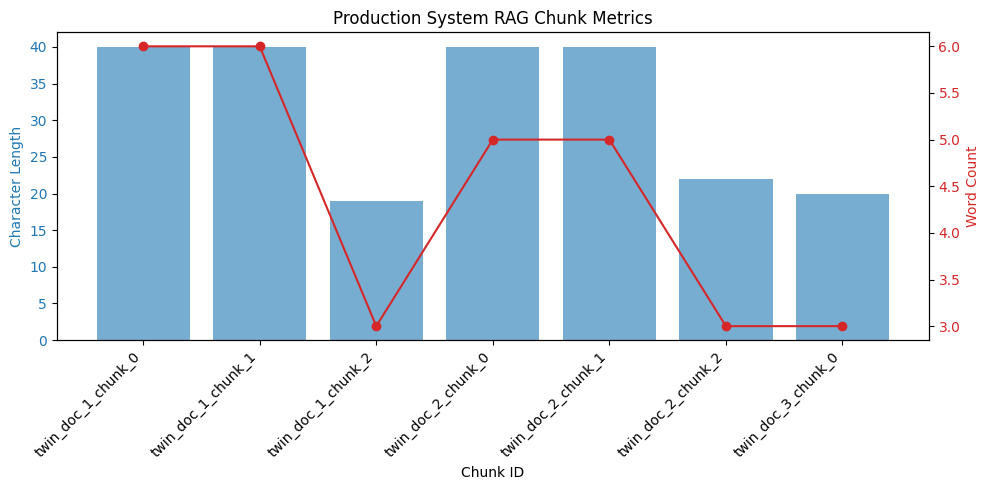

In [9]:
import logging
import matplotlib.pyplot as plt
from typing import List, Dict, Any

# Configure a basic logging setup
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

class ProductionSystem:
    """
    A complete, production-ready RAG Loading, Preprocessing, and Chunking system.
    """
    def __init__(self, preprocessor: SimpleTextPreprocessor, chunk_size: int = 50, chunk_overlap: int = 10):
        if not isinstance(preprocessor, SimpleTextPreprocessor):
            raise TypeError("preprocessor must be an instance of SimpleTextPreprocessor")
        self.preprocessor = preprocessor
        self.chunk_size = chunk_size
        self.chunk_overlap = chunk_overlap
        self.logs = []

    def _log(self, message: str, level: str = "INFO"):
        log_msg = f"[{level}] {message}"
        self.logs.append(log_msg)
        print(log_msg)

    def chunk_text(self, text: str) -> List[str]:
        """
        Splits text into chunks of roughly `chunk_size` characters with `chunk_overlap` overlap.
        """
        if not text:
            return []

        chunks = []
        start = 0
        while start < len(text):
            end = start + self.chunk_size
            chunks.append(text[start:end])
            start += (self.chunk_size - self.chunk_overlap)
            if start >= len(text) or self.chunk_size <= self.chunk_overlap:
                break
        return chunks

    def process_pipeline(self, raw_documents: List[Dict[str, Any]]) -> List[Dict[str, Any]]:
        """
        Runs the complete RAG loading, preprocessing, chunking, and metadata extraction pipeline.
        """
        self._log("Starting production RAG pipeline execution...")

        if not isinstance(raw_documents, list):
            self._log("Pipeline failed: Input documents must be a list", "ERROR")
            raise TypeError("Input documents must be a list")

        all_chunks_metadata = []

        for idx, doc in enumerate(raw_documents):
            if not isinstance(doc, dict) or "id" not in doc or "text" not in doc:
                self._log(f"Skipping invalid document at index {idx}", "WARNING")
                continue

            doc_id = doc["id"]
            raw_text = doc["text"]

            self._log(f"Processing document '{doc_id}'...")

            # Step 1: Preprocess
            try:
                cleaned_text = self.preprocessor.process(raw_text)
            except Exception as e:
                self._log(f"Error processing text for {doc_id}: {e}", "ERROR")
                continue

            # Step 2: Chunk
            chunks = self.chunk_text(cleaned_text)
            self._log(f"Split document '{doc_id}' into {len(chunks)} chunks.")

            # Step 3: Package metadata
            for chunk_idx, chunk in enumerate(chunks):
                all_chunks_metadata.append({
                    "chunk_id": f"{doc_id}_chunk_{chunk_idx}",
                    "parent_doc_id": doc_id,
                    "content": chunk,
                    "char_length": len(chunk),
                    "word_count": len(chunk.split())
                })

        self._log("RAG pipeline completed successfully!")
        return all_chunks_metadata

    def visualize_metrics(self, chunks: List[Dict[str, Any]]):
        """
        Generates a visualization showing the lengths of generated chunks.
        """
        if not chunks:
            self._log("No chunk data available to visualize", "WARNING")
            return

        chunk_ids = [c["chunk_id"] for c in chunks]
        lengths = [c["char_length"] for c in chunks]
        word_counts = [c["word_count"] for c in chunks]

        fig, ax1 = plt.subplots(figsize=(10, 5))

        color = 'tab:blue'
        ax1.set_xlabel('Chunk ID')
        ax1.set_ylabel('Character Length', color=color)
        ax1.bar(chunk_ids, lengths, color=color, alpha=0.6, label='Char Length')
        ax1.tick_params(axis='y', labelcolor=color)
        plt.xticks(rotation=45, ha='right')

        ax2 = ax1.twinx()
        color = 'tab:red'
        ax2.set_ylabel('Word Count', color=color)
        ax2.plot(chunk_ids, word_counts, color=color, marker='o', label='Word Count')
        ax2.tick_params(axis='y', labelcolor=color)

        plt.title('Production System RAG Chunk Metrics')
        fig.tight_layout()
        plt.show()

# --- Test your production system ---
try:
    # 1. Setup system components
    prep = SimpleTextPreprocessor(lowercase=True, remove_punctuation=True)
    prod_system = ProductionSystem(preprocessor=prep, chunk_size=40, chunk_overlap=10)

    # 2. Define standard test dataset
    production_docs = [
        {"id": "twin_doc_1", "text": "The digital twin mimics physical assets using advanced sensory feedback systems."},
        {"id": "twin_doc_2", "text": "Real-time data synchronization helps predictive maintenance protocols work reliably."},
        {"id": "twin_doc_3", "text": "Invalid payload data..."} # Short doc
    ]

    # 3. Run Pipeline
    processed_chunks = prod_system.process_pipeline(production_docs)

    # 4. Display Results
    print("\n--- Processed Chunks ---")
    print(json.dumps(processed_chunks, indent=2))

    # 5. Visualize
    prod_system.visualize_metrics(processed_chunks)

except Exception as e:
    print(f"An error occurred during execution: {e}")

---
## Summary & Key Takeaways

### What We Learned:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete RAG architecture and pipeline System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code